<a href="https://colab.research.google.com/github/lokeshchowdary9220/AML-Lab/blob/main/lab4(Assignment).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
#Importing Required Dataset Data

df = pd.read_csv("/content/archive.zip")
df.head()



,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [5]:
#Checking Dataset shape and information
print("Number of rows and columns:", df.shape)


Number of rows and columns: (569, 32)


                             DATA PREPROCESSING

In [6]:
#Checking Missing values
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


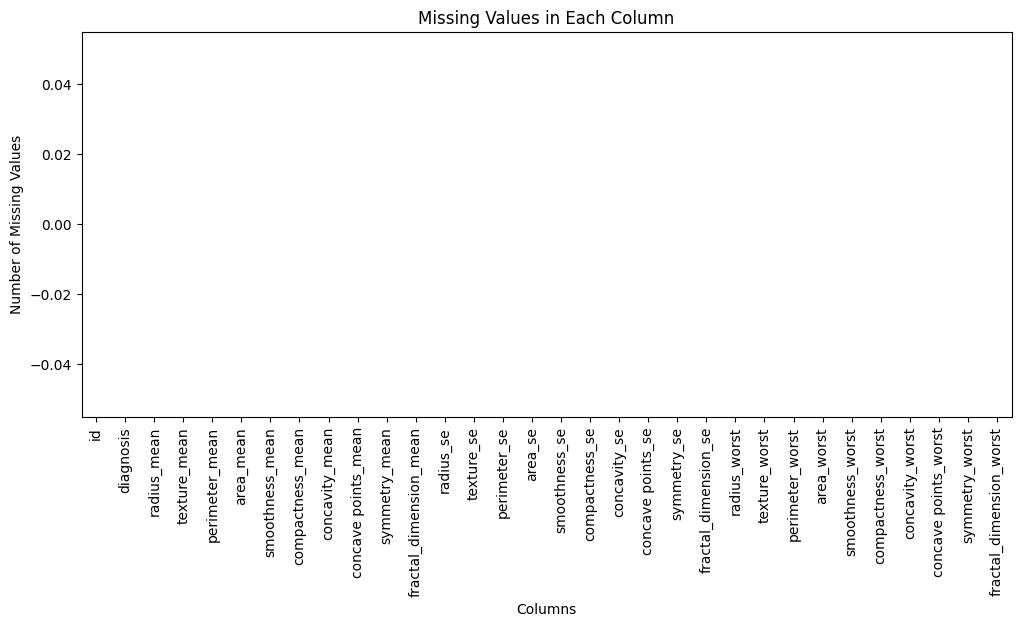

In [7]:
#Graph for Missing  Values
df.isnull().sum().plot(kind="bar", figsize=(12, 5))

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=90)
plt.show()

Duplicate rows: 0


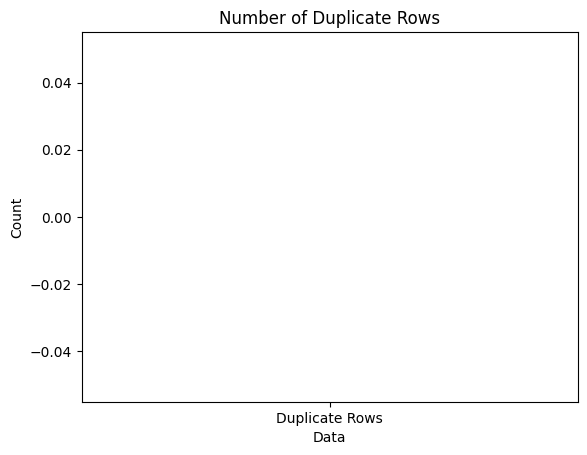

In [8]:
#Checking Duplicate Values and Visualization
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

plt.bar(["Duplicate Rows"], [duplicate_count])
plt.title("Number of Duplicate Rows")
plt.xlabel("Data")
plt.ylabel("Count")
plt.show()

In [9]:
#checking Column names
print(df.columns)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')


In [10]:
#Checking Class distribution
print(df["diagnosis"].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


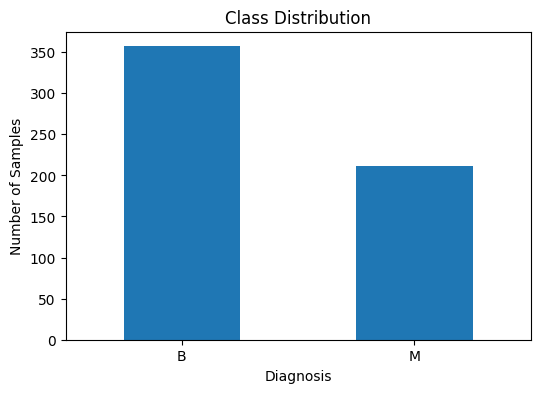

In [11]:
#Plot for class Distribution
plt.figure(figsize=(6, 4))

df["diagnosis"].value_counts().plot(kind="bar")

plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.show()

In [12]:
# Convert categorical diagnosis values into numerical values
df["diagnosis"] = df["diagnosis"].map({
    "M": 1,  # Malignant
    "B": 0   # Benign
})

# Display the first five encoded diagnosis values
df["diagnosis"].head()

,diagnosis
0,1
1,1
2,1
3,1
4,1


                           DECISION TREE MODEL

In [14]:
# Define input data
x = df.drop("diagnosis", axis=1)

# Define target data
y = df["diagnosis"]

In [17]:
# Split the dataset into training and testing data
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42)

In [20]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

decision_model = DecisionTreeClassifier(random_state=42)

decision_model.fit(x_train, y_train)

decision_pred = decision_model.predict(x_test)

In [21]:
# Predict using the Decision Tree model
decision_pred = decision_model.predict(x_test)

print(decision_pred)

[0 1 1 0 0 1 1 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1
 0 1 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 1 0 0 1 1 0 1
 0 0 0 0 0 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0 0 0 1 1 0 1
 0 0 1]


##  Decision tree Model Evaluation

In [27]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

# Evaluate the Decision Tree model
print('Accuracy Score:', accuracy_score(y_test, decision_pred))
print('Recall Score:', recall_score(y_test, decision_pred, average='weighted'))
print('Precision Score:', precision_score(y_test, decision_pred, average='weighted'))
print('F1 Score:', f1_score(y_test, decision_pred, average='weighted'))

# Confusion Matrix
print('Confusion Matrix:\n', confusion_matrix(y_test, decision_pred))

Accuracy Score: 0.9385964912280702
Recall Score: 0.9385964912280702
Precision Score: 0.9390179995443153
F1 Score: 0.938731642017737
Confusion Matrix:
 [[67  4]
 [ 3 40]]


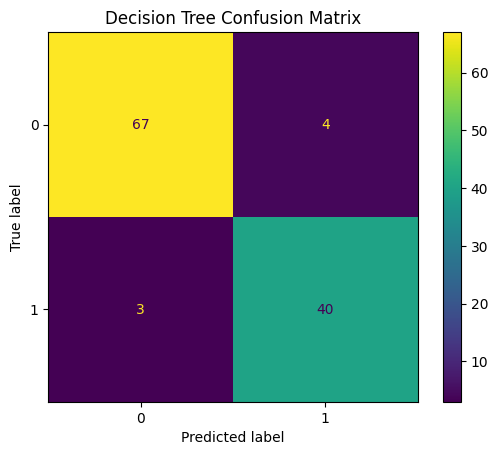

In [24]:
# Confusion Matrix for Decision Tree

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, decision_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot()

plt.title("Decision Tree Confusion Matrix")

plt.show()

                      LOGISTIC REGRESSION MODEL

In [25]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=10000)

logistic_model.fit(x_train, y_train)

logistic_pred = logistic_model.predict(x_test)

In [28]:
# Predict using the Logistic Regression model
logistic_pred = logistic_model.predict(x_test)

print(logistic_pred)

[0 1 1 0 0 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1
 0 1 0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 1 0 0 0 1 1 0 0 1 1 0 0
 0 0 0 1 0 0 1 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0 0 0 1 0 0 1
 0 0 1]


## Logistic Regression Model Evaluation

In [29]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

# Evaluation of Logistic Regression model
print('Accuracy Score:', accuracy_score(y_test, logistic_pred))
print('Recall Score:', recall_score(y_test, logistic_pred, average='weighted'))
print('Precision Score:', precision_score(y_test, logistic_pred, average='weighted'))
print('F1 Score:', f1_score(y_test, logistic_pred, average='weighted'))

# Confusion Matrix
print('Confusion Matrix:\n', confusion_matrix(y_test, logistic_pred))

Accuracy Score: 0.956140350877193
Recall Score: 0.956140350877193
Precision Score: 0.9569049312470365
F1 Score: 0.9558014271241044
Confusion Matrix:
 [[70  1]
 [ 4 39]]


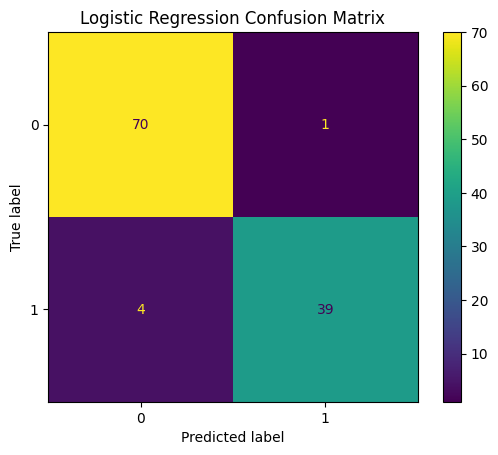

In [30]:
# Confusion Matrix for Logistic Regression

cm = confusion_matrix(y_test, logistic_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot()

plt.title("Logistic Regression Confusion Matrix")

plt.show()

            Comparison of Logistic Regression and Decision Tree Model Performance

In [31]:
# Compare the performance of Logistic Regression and Decision Tree models

from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
import pandas as pd

# Create comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],

    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, decision_pred)
    ],

    "Recall": [
        recall_score(y_test, logistic_pred, average="weighted"),
        recall_score(y_test, decision_pred, average="weighted")
    ],

    "Precision": [
        precision_score(y_test, logistic_pred, average="weighted"),
        precision_score(y_test, decision_pred, average="weighted")
    ],

    "F1 Score": [
        f1_score(y_test, logistic_pred, average="weighted"),
        f1_score(y_test, decision_pred, average="weighted")
    ]
})

# Display the comparison table
comparison


,Model,Accuracy,Recall,Precision,F1 Score
0,Logistic Regression,0.956140,0.956140,0.956905,0.955801
1,Decision Tree,0.938596,0.938596,0.939018,0.938732


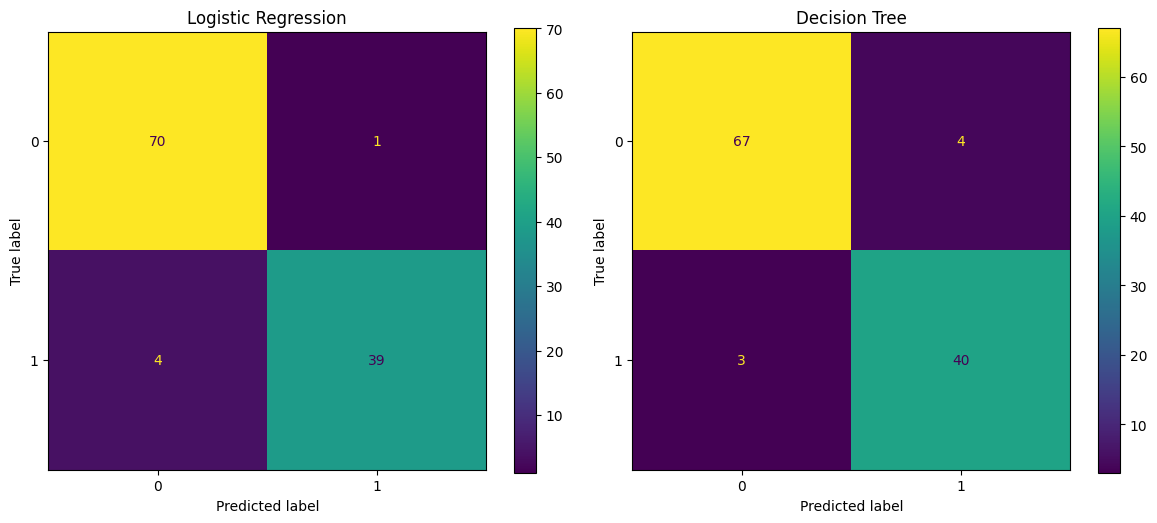

In [32]:
# Compare the confusion matrices of Logistic Regression and Decision Tree models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrices
logistic_cm = confusion_matrix(y_test, logistic_pred)
decision_cm = confusion_matrix(y_test, decision_pred)

# Create side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression
ConfusionMatrixDisplay(confusion_matrix=logistic_cm).plot(ax=axes[0])
axes[0].set_title("Logistic Regression")

# Decision Tree
ConfusionMatrixDisplay(confusion_matrix=decision_cm).plot(ax=axes[1])
axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()

# Conclusion

Both Logistic Regression and Decision Tree models were evaluated using Accuracy, Recall, Precision, and F1 Score. Based on the evaluation results, the Logistic Regression model performed better than the Decision Tree model.

Logistic Regression achieved an Accuracy and Recall of 95.61%, a Precision of 95.69%, and an F1 Score of 95.58%. In comparison, the Decision Tree achieved an Accuracy and Recall of 93.86%, a Precision of 93.90%, and an F1 Score of 93.87%.

Since Logistic Regression obtained higher values for all evaluation metrics, it demonstrated better overall performance on the Breast Cancer dataset. Therefore, Logistic Regression can be considered the better-performing model for this classification task.